# Практическое задание: коллаборативная фильтрация на MovieLens

В этом ноутбуке реализована рекомендательная система на датасете **MovieLens `ml-latest-small`** с использованием библиотеки `surprise`.

В работе выполнены этапы:

1. Загрузка и подготовка данных.
2. Исследовательский анализ данных.
3. Анализ разреженности матрицы пользователь-фильм.
4. Обучение двух моделей коллаборативной фильтрации:
   - user-based;
   - item-based.
5. Кросс-валидация на 5 фолдах.
6. Сравнение моделей по RMSE и MAE.
7. Генерация рекомендаций для случайного пользователя.
8. Итоговые выводы.


## 1. Установка и импорт библиотек

In [ ]:
!pip install scikit-surprise -q

import os
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from surprise import Dataset, Reader
from surprise import KNNBasic
from surprise.model_selection import cross_validate

# фиксируем random seed, чтобы результаты были более воспроизводимыми.
RANDOM_STATE = 42

# настраиваем отображение графиков прямо в ноутбуке.
%matplotlib inline


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 10.0 MB/s eta 0:00:00


## 2. Загрузка и распаковка архива

 файл из https://grouplens.org/datasets/movielens/latest ; называется ml-latest-small.zip.


In [ ]:
zip_path = '/content/ml-latest-small.zip'
extract_path = '/content/ml-latest-small'

# проверка
if not os.path.exists(zip_path):
    raise FileNotFoundError(
        'Файл ml-latest-small.zip не найден. Загрузите zip-файл в Colab и проверьте название файла.'
    )

# если не существует паапки
os.makedirs(extract_path, exist_ok=True)

# распаковка
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print('Архив успешно распакован.')
print('Содержимое папки:', os.listdir(extract_path))


Архив успешно распакован.
Содержимое папки: ['ml-latest-small']


## 3. Поиск файлов **ratings.csv** и **movies.csv**

In [ ]:
# переменные для будущих путей к файлам.
ratings_path = None
movies_path = None

# проходим по всем папкам и файлам внутри extract_path.
for root, dirs, files in os.walk(extract_path):
    # если в текущей папке найден ratings.csv, сохраняем полный путь к нему.
    if 'ratings.csv' in files:
        ratings_path = os.path.join(root, 'ratings.csv')

    # если в текущей папке найден movies.csv, сохраняем полный путь к нему
    if 'movies.csv' in files:
        movies_path = os.path.join(root, 'movies.csv')

# проверка что ratings.csv найден
if ratings_path is None:
    raise FileNotFoundError('Файл ratings.csv не найден внутри архива.')

# проверка что movies.csv найден.
if movies_path is None:
    raise FileNotFoundError('Файл movies.csv не найден внутри архива.')

# вывод найденных путей
print('Путь к ratings.csv:', ratings_path)
print('Путь к movies.csv:', movies_path)


Путь к ratings.csv: /content/ml-latest-small/ml-latest-small/ratings.csv
Путь к movies.csv: /content/ml-latest-small/ml-latest-small/movies.csv


## 4. Чтение данных

In [ ]:
# загружаем таблицу с оценками пользователей.
ratings = pd.read_csv(ratings_path)

# загружаем таблицу с названиями фильмов и жанрами.
movies = pd.read_csv(movies_path)

# первые строки таблицы ratings.
ratings.head()


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


In [ ]:
# первые строки таблицы movies.
movies.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [ ]:
# проверяем размер таблицы ratings: количество строк и столбцов.
print('Размер ratings:', ratings.shape)

# проверяем размер таблицы movies: количество строк и столбцов.
print('Размер movies:', movies.shape)

# проверяем типы данных и наличие пропусков в ratings.
ratings.info()


Размер ratings: (100836, 4)
Размер movies: (9742, 3)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [ ]:
# проверяем наличие пропущенных значений в ratings.
print('Пропуски в ratings:')
print(ratings.isna().sum())

# проверяем наличие пропущенных значений в movies.
print('Пропуски в movies:')
print(movies.isna().sum())


Пропуски в ratings:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64
Пропуски в movies:
movieId    0
title      0
genres     0
dtype: int64


## 5. Базовая статистика по данным

In [ ]:
# количество уникальных пользователей
n_users = ratings['userId'].nunique()

# количество уникальных фильмов, которые получили оценки
n_items = ratings['movieId'].nunique()

# общее количество оценок
n_ratings = len(ratings)

# минимальная оценка
min_rating = ratings['rating'].min()

# максимальная оценка
max_rating = ratings['rating'].max()

# средняя оценка
mean_rating = ratings['rating'].mean()

# вывод результатов
print('Количество пользователей:', n_users)
print('Количество фильмов с оценками:', n_items)
print('Количество оценок:', n_ratings)
print('Минимальная оценка:', min_rating)
print('Максимальная оценка:', max_rating)
print('Средняя оценка:', round(mean_rating, 3))


Количество пользователей: 610
Количество фильмов с оценками: 9724
Количество оценок: 100836
Минимальная оценка: 0.5
Максимальная оценка: 5.0
Средняя оценка: 3.502


## 6. EDA: распределение оценок

In [ ]:
# сколько раз встречается каждая оценка
rating_counts = ratings['rating'].value_counts().sort_index()

# таблица распределения оценок
rating_counts

,count
rating,
0.5,1370
1.0,2811
1.5,1791
2.0,7551
2.5,5550
3.0,20047
3.5,13136
4.0,26818
4.5,8551


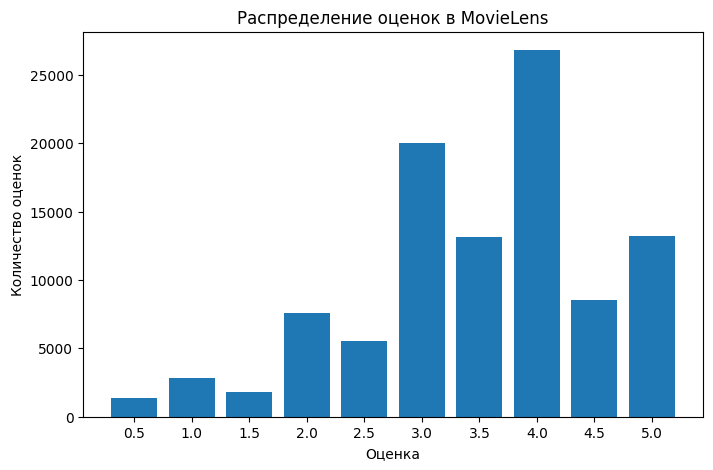

In [ ]:
# Строим столбчатую диаграмму распределения оценок.
plt.figure(figsize=(8, 5))
plt.bar(rating_counts.index.astype(str), rating_counts.values)
plt.title('Распределение оценок в MovieLens')
plt.xlabel('Оценка')
plt.ylabel('Количество оценок')
plt.show()


### Интерпретация распределения оценок

По графику можно оценить, какие оценки пользователи ставят чаще всего. Обычно в MovieLens пользователи чаще ставят положительные оценки, поэтому распределение может быть смещено в сторону 3.0 - 4.0 баллов и выше.


## 7. EDA: активность пользователей

In [ ]:
# количество оценок от каждого пользователя
user_activity = ratings.groupby('userId')['rating'].count().sort_values(ascending=False)

# 10 самых активных пользователей
user_activity.head(10)


,rating
userId,
414,2698
599,2478
474,2108
448,1864
274,1346
610,1302
68,1260
380,1218
606,1115


In [ ]:
# описательная статистика по активности пользователей
user_activity.describe()


,rating
count,610.000000
mean,165.304918
std,269.480584
min,20.000000
25%,35.000000
50%,70.500000
75%,168.000000
max,2698.000000


### Интерпретация активности пользователей

Пользователи оценивают разное количество фильмов. Часть пользователей ставит относительно мало оценок, а небольшая часть пользователей является очень активной. Это типично для рекомендательных систем.


## 8. EDA: самые популярные фильмы

In [ ]:
# количество оценок для каждого фильма
movie_popularity = ratings.groupby('movieId')['rating'].count().reset_index()

# переименовываем столбец rating в rating_count
movie_popularity = movie_popularity.rename(columns={'rating': 'rating_count'})

# добавляем к таблице названия фильмов
movie_popularity = movie_popularity.merge(movies, on='movieId', how='left')

# сортировка фильмов по количеству оценок от большего к меньшему
movie_popularity = movie_popularity.sort_values(by='rating_count', ascending=False)

# 10 самых популярных фильмов
movie_popularity[['movieId', 'title', 'genres', 'rating_count']].head(10)


,movieId,title,genres,rating_count
314,356,Forrest Gump (1994),Comedy|Drama|Romance|War,329
277,318,"Shawshank Redemption, The (1994)",Crime|Drama,317
257,296,Pulp Fiction (1994),Comedy|Crime|Drama|Thriller,307
510,593,"Silence of the Lambs, The (1991)",Crime|Horror|Thriller,279
1938,2571,"Matrix, The (1999)",Action|Sci-Fi|Thriller,278
224,260,Star Wars: Episode IV - A New Hope (1977),Action|Adventure|Sci-Fi,251
418,480,Jurassic Park (1993),Action|Adventure|Sci-Fi|Thriller,238
97,110,Braveheart (1995),Action|Drama|War,237
507,589,Terminator 2: Judgment Day (1991),Action|Sci-Fi,224
461,527,Schindler's List (1993),Drama|War,220


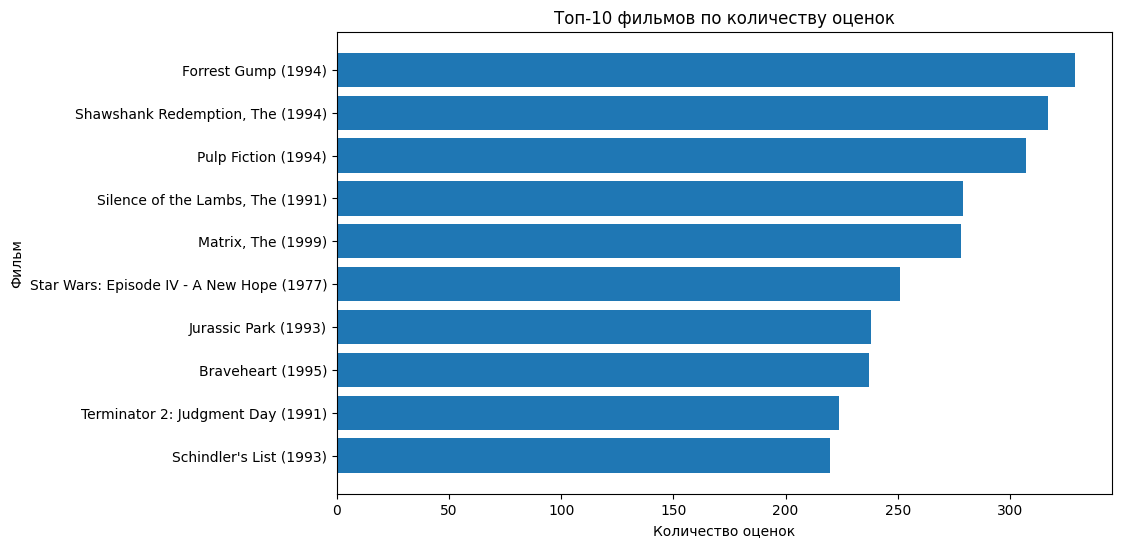

In [ ]:
# график топ-10 самых популярных фильмов
top_10_movies = movie_popularity.head(10)

plt.figure(figsize=(10, 6))
plt.barh(top_10_movies['title'], top_10_movies['rating_count'])
plt.title('Топ-10 фильмов по количеству оценок')
plt.xlabel('Количество оценок')
plt.ylabel('Фильм')
plt.gca().invert_yaxis()
plt.show()


## 9. Анализ разреженности матрицы пользователь-фильм

В рекомендательных системах матрица пользователь-фильм почти всегда разреженная: большинство пользователей оценили только небольшую долю всех фильмов.

Разреженность можно рассчитать так:

```text
sparsity = 1 - количество_имеющихся_оценок / количество_возможных_оценок
```


In [ ]:
# максимально возможное количество оценок
# Это количество пользователей, умноженное на количество фильмов
possible_ratings = n_users * n_items

# доля заполненных ячеек матрицы
density = n_ratings / possible_ratings

# разреженность матрицы
sparsity = 1 - density

# результаты
print('Возможное количество оценок:', possible_ratings)
print('Фактическое количество оценок:', n_ratings)
print('Плотность матрицы:', round(density * 100, 4), '%')
print('Разреженность матрицы:', round(sparsity * 100, 4), '%')


Возможное количество оценок: 5931640
Фактическое количество оценок: 100836
Плотность матрицы: 1.7 %
Разреженность матрицы: 98.3 %


### Вывод по разреженности

Матрица пользователь-фильм является сильно разреженной, так как пользователи оценили только небольшую часть всех возможных пар пользователь-фильм. Именно поэтому для таких задач применяются специальные рекомендательные алгоритмы.


## 10. Подготовка данных для библиотеки `surprise`

Библиотека **surprise** ожидает данные в формате:

```text
user_id, item_id, rating
```

В нашем случае:

- **userId** — пользователь;
- **movieId** — фильм;
- **rating** — оценка.


In [ ]:
# создаем объект Reader и указываем диапазон оценок в датасете
reader = Reader(rating_scale=(min_rating, max_rating))

# передаем в surprise только три нужных столбца: userId, movieId, rating
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)

# проверяем, что объект Dataset создан
print('Данные успешно подготовлены для surprise.')


Данные успешно подготовлены для surprise.


## 11. Модель 1: User-based collaborative filtering

User-based подход ищет похожих пользователей. Если пользователь A похож на пользователя B, то фильмы, понравившиеся B, могут быть рекомендованы A.


In [ ]:
# настраиваем параметры сходства для user-based модели
user_based_sim_options = {
    'name': 'cosine',        # используем cosine similarity
    'user_based': True      # True означает, что сравниваем пользователей
}

# user-based модель KNNBasic
user_based_model = KNNBasic(
    sim_options=user_based_sim_options,
    verbose=False
)

# Вывод параметров модели
print('User-based модель создана.')


User-based модель создана.


## 12. Модель 2: Item-based collaborative filtering

Item-based подход ищет похожие фильмы. Если пользователь высоко оценил один фильм, ему можно рекомендовать похожие фильмы.


In [ ]:
# настраиваем параметры сходства для item-based модели
item_based_sim_options = {
    'name': 'cosine',        # используем cosine similarity
    'user_based': False     # False означает, что сравниваем фильмы
}

# создаем item-based модель KNNBasic
item_based_model = KNNBasic(
    sim_options=item_based_sim_options,
    verbose=False
)

# Вывод параметров модели
print('Item-based модель создана.')


Item-based модель создана.


## 13. Кросс-валидация моделей на 5 фолдах

Для объективной оценки используем 5-fold cross-validation.

Основные метрики:

- **RMSE** — среднеквадратичная ошибка, более чувствительна к большим ошибкам;
- **MAE** — средняя абсолютная ошибка, показывает средний размер ошибки в баллах рейтинга.

Чем ниже RMSE и MAE, тем лучше модель.


In [ ]:
# выполнение кросс-валидации для user-based модели
user_based_cv = cross_validate(
    user_based_model,       # модель
    data,                   # данные surprise
    measures=['RMSE', 'MAE'],# метрики качества
    cv=5,                   # количество фолдов
    verbose=True,           # выводим результаты по фолдам
    n_jobs=-1               # используем все доступные ядра процессора
)


Evaluating RMSE, MAE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9757  0.9789  0.9688  0.9690  0.9740  0.9733  0.0039  
MAE (testset)     0.7499  0.7571  0.7460  0.7460  0.7495  0.7497  0.0041  
Fit time          0.46    0.34    0.16    0.41    0.47    0.37    0.11    
Test time         1.48    1.32    2.32    2.39    1.64    1.83    0.44    


In [ ]:
# выполнение кросс-валидации для item-based модели
item_based_cv = cross_validate(
    item_based_model,       # модель
    data,                   # данные surprise
    measures=['RMSE', 'MAE'],# метрики качества
    cv=5,                   # количество фолдов
    verbose=True,           # выводим результаты по фолдам
    n_jobs=-1               # используем все доступные ядра процессора
)


Evaluating RMSE, MAE of algorithm KNNBasic on 5 split(s).

                  Fold 1  Fold 2  Fold 3  Fold 4  Fold 5  Mean    Std     
RMSE (testset)    0.9853  0.9735  0.9798  0.9671  0.9797  0.9771  0.0062  
MAE (testset)     0.7685  0.7583  0.7650  0.7530  0.7632  0.7616  0.0054  
Fit time          8.69    9.31    13.56   12.51   3.68    9.55    3.47    
Test time         6.87    7.00    6.12    5.99    3.88    5.97    1.12    


## 14. Итоговая таблица сравнения моделей

In [ ]:
# создаем таблицу с результатами кросс-валидации
results = pd.DataFrame({
    'model': ['User-based KNN', 'Item-based KNN'],
    'mean_RMSE': [
        np.mean(user_based_cv['test_rmse']),
        np.mean(item_based_cv['test_rmse'])
    ],
    'mean_MAE': [
        np.mean(user_based_cv['test_mae']),
        np.mean(item_based_cv['test_mae'])
    ],
    'fit_time_mean': [
        np.mean(user_based_cv['fit_time']),
        np.mean(item_based_cv['fit_time'])
    ],
    'test_time_mean': [
        np.mean(user_based_cv['test_time']),
        np.mean(item_based_cv['test_time'])
    ]
})

# округляем числовые значения для удобного отображения
results_rounded = results.round(4)

# итоговая таблица
results_rounded


,model,mean_RMSE,mean_MAE,fit_time_mean,test_time_mean
0,User-based KNN,0.9733,0.7497,0.3681,1.8314
1,Item-based KNN,0.9771,0.7616,9.5475,5.9716


In [ ]:
# определяем лучшую модель по RMSE
best_model_by_rmse = results.loc[results['mean_RMSE'].idxmin(), 'model']

# определяем лучшую модель по MAE
best_model_by_mae = results.loc[results['mean_MAE'].idxmin(), 'model']

# результат
print('Лучшая модель по RMSE:', best_model_by_rmse)
print('Лучшая модель по MAE:', best_model_by_mae)


Лучшая модель по RMSE: User-based KNN
Лучшая модель по MAE: User-based KNN


## 15. Обучение моделей на полном наборе данных

После кросс-валидации обучим модели на всех доступных оценках, чтобы затем получить рекомендации для конкретного пользователя.


In [ ]:
# строим полный trainset из всех данных
trainset = data.build_full_trainset()

# новая user-based модель для обучения на полном наборе
final_user_based_model = KNNBasic(
    sim_options=user_based_sim_options,
    verbose=False
)

# обучаем user-based модель на полном trainset
final_user_based_model.fit(trainset)

# создаем новую item-based модель для обучения на полном наборе
final_item_based_model = KNNBasic(
    sim_options=item_based_sim_options,
    verbose=False
)

# обучаем item-based модель на полном trainset.
final_item_based_model.fit(trainset)

# сообщение об успешном обучении
print('Финальные модели обучены на полном наборе данных.')


Финальные модели обучены на полном наборе данных.


## 16. Выбор случайного пользователя для проверки рекомендаций

In [ ]:
# выбираем случайного пользователя из датасета
random_user_id = ratings['userId'].sample(1, random_state=RANDOM_STATE).iloc[0]

# выводим выбранного пользователя
print('Выбранный пользователь:', random_user_id)

# смотрим фильмы, которые этот пользователь уже оценил
user_seen_movies = ratings[ratings['userId'] == random_user_id].merge(movies, on='movieId', how='left')

# показываем 10 фильмов с самыми высокими оценками этого пользователя
user_seen_movies.sort_values(by='rating', ascending=False)[['movieId', 'title', 'genres', 'rating']].head(10)


Выбранный пользователь: 432


,movieId,title,genres,rating
257,91658,"Girl with the Dragon Tattoo, The (2011)",Drama|Thriller,5.0
231,71379,Paranormal Activity (2009),Horror|Thriller,5.0
38,912,Casablanca (1942),Drama|Romance,5.0
209,57274,[REC] (2007),Drama|Horror|Thriller,5.0
173,8533,"Notebook, The (2004)",Drama|Romance,5.0
194,45503,Peaceful Warrior (2006),Drama,5.0
20,364,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,5.0
247,81591,Black Swan (2010),Drama|Thriller,5.0
111,3949,Requiem for a Dream (2000),Drama,5.0
67,1873,"Misérables, Les (1998)",Crime|Drama|Romance|War,5.0


## 17. Функция для получения рекомендаций

Функция ниже:

1. Находит фильмы, которые пользователь еще не оценивал.
2. Предсказывает оценку для каждого такого фильма.
3. Сортирует фильмы по предсказанной оценке.
4. Возвращает топ-N рекомендаций.


In [ ]:
# создаем функцию для получения топ-N рекомендаций
def get_top_n_recommendations(model, user_id, ratings_df, movies_df, n=10):
    # Получаем множество фильмов, которые пользователь уже оценил
    rated_movies = set(ratings_df[ratings_df['userId'] == user_id]['movieId'])

    # получаем множество всех фильмов из таблицы movies
    all_movies = set(movies_df['movieId'])

    # оставляем только фильмы, которые пользователь еще не оценивал
    movies_to_predict = list(all_movies - rated_movies)

    # создаем пустой список для предсказаний
    predictions = []

    # проходим по каждому фильму, который пользователь еще не оценивал
    for movie_id in movies_to_predict:
        # Предсказываем рейтинг пользователя для фильма
        prediction = model.predict(user_id, movie_id)

        # сохраняем movieId и предсказанную оценку
        predictions.append((movie_id, prediction.est))

    # преобразуем список предсказаний в DataFrame
    recommendations = pd.DataFrame(predictions, columns=['movieId', 'predicted_rating'])

    # добавляем к рекомендациям названия фильмов и жанры
    recommendations = recommendations.merge(movies_df, on='movieId', how='left')

    # сортируем рекомендации по предсказанной оценке от большей к меньшей
    recommendations = recommendations.sort_values(by='predicted_rating', ascending=False)

    # возвращаем top-N рекомендаций
    return recommendations[['movieId', 'title', 'genres', 'predicted_rating']].head(n)


## 18. Рекомендации User-based модели

In [ ]:
# топ-10 рекомендаций для выбранного пользователя через user-based модель
user_based_recommendations = get_top_n_recommendations(
    model=final_user_based_model,
    user_id=random_user_id,
    ratings_df=ratings,
    movies_df=movies,
    n=10
)

# округляем предсказанные рейтинги
user_based_recommendations['predicted_rating'] = user_based_recommendations['predicted_rating'].round(3)

# рекомендации
user_based_recommendations


,movieId,title,genres,predicted_rating
30,131098,Saving Santa (2013),Animation|Children|Comedy,5.0
7376,149350,Lumberjack Man (2015),Comedy|Horror,5.0
7369,50999,"Ugly Duckling and Me!, The (2006)",Animation|Comedy,5.0
7171,147410,A Perfect Day (2015),Comedy|Drama,5.0
7156,147330,Sherlock Holmes and Dr. Watson: Acquaintance (...,Crime,5.0
7154,147328,The Adventures of Sherlock Holmes and Dr. Wats...,Crime,5.0
7152,147326,The Adventures of Sherlock Holmes and Doctor W...,Crime|Mystery,5.0
9361,163112,Winnie the Pooh Goes Visiting (1971),Animation,5.0
9353,163072,Winnie Pooh (1969),Animation|Children,5.0
9321,64501,Che: Part Two (2008),Drama|War,5.0


## 19. Рекомендации Item-based модели

In [ ]:
# получаем топ-10 рекомендаций для выбранного пользователя через item-based модель.
item_based_recommendations = get_top_n_recommendations(
    model=final_item_based_model,
    user_id=random_user_id,
    ratings_df=ratings,
    movies_df=movies,
    n=10
)

# округляем предсказанные рейтинги.
item_based_recommendations['predicted_rating'] = item_based_recommendations['predicted_rating'].round(3)

# рекомендации
item_based_recommendations


,movieId,title,genres,predicted_rating
933,1140,Entertaining Angels: The Dorothy Day Story (1996),Drama,4.500
1236,1519,Broken English (1996),Drama,4.500
3165,3899,Circus (2000),Crime|Drama|Thriller,4.500
9126,63239,Cinderella (1997),Children|Fantasy|Musical|Romance,4.167
4772,6158,"Jungle Book 2, The (2003)",Animation|Children,4.167
7056,113829,"One I Love, The (2014)",Comedy|Drama|Romance,4.125
7113,114265,Laggies (2014),Comedy|Romance,4.125
8463,124851,Delirium (2014),Adventure|Romance|Sci-Fi,4.125
3318,4083,Best Seller (1987),Thriller,4.071
2411,2969,"Man and a Woman, A (Un homme et une femme) (1966)",Drama|Romance,4.071


## 20. Интерпретация рекомендаций для выбранного пользователя

In [ ]:
# смотрим жанры фильмов, которые пользователь оценил наиболее высоко
user_high_rated = user_seen_movies[user_seen_movies['rating'] >= 4.0]

# выводим фильмы, которые пользователь оценил на 4 или выше
user_high_rated[['title', 'genres', 'rating']].sort_values(by='rating', ascending=False).head(15)


,title,genres,rating
20,"Lion King, The (1994)",Adventure|Animation|Children|Drama|Musical|IMAX,5.0
209,[REC] (2007),Drama|Horror|Thriller,5.0
111,Requiem for a Dream (2000),Drama,5.0
67,"Misérables, Les (1998)",Crime|Drama|Romance|War,5.0
257,"Girl with the Dragon Tattoo, The (2011)",Drama|Thriller,5.0
247,Black Swan (2010),Drama|Thriller,5.0
231,Paranormal Activity (2009),Horror|Thriller,5.0
173,"Notebook, The (2004)",Drama|Romance,5.0
194,Peaceful Warrior (2006),Drama,5.0
73,"Exorcist, The (1973)",Horror|Mystery,5.0


### Краткая интерпретация

Для выбранного пользователя рекомендации можно интерпретировать через сравнение:

1. Какие фильмы он уже оценивал высоко.
2. Какие жанры встречаются среди этих фильмов.
3. Какие фильмы предложила user-based модель.
4. Какие фильмы предложила item-based модель.

Если рекомендованные фильмы похожи по жанрам или по общему профилю интересов пользователя на фильмы с высокими оценками, то рекомендации выглядят логичными.


## 21. Финальные выводы

In [ ]:
# выводим итоговую таблицу еще раз
results_rounded


,model,mean_RMSE,mean_MAE,fit_time_mean,test_time_mean
0,User-based KNN,0.9733,0.7497,0.3681,1.8314
1,Item-based KNN,0.9771,0.7616,9.5475,5.9716


### Итоговый вывод

В работе были обучены и сравнены две модели коллаборативной фильтрации:

- **User-based KNN** — модель, основанная на сходстве пользователей.
- **Item-based KNN** — модель, основанная на сходстве фильмов.

Обе модели были оценены с помощью 5-fold cross-validation по метрикам **RMSE** и **MAE**.

Модель с меньшими значениями RMSE и MAE можно считать более точной, потому что она в среднем меньше ошибается при предсказании пользовательских оценок.

По итоговой таблице нужно выбрать подход, который показал меньшую ошибку. Если лучшая модель по RMSE и MAE совпадает, вывод однозначный. Если одна модель лучше по RMSE, а другая по MAE, стоит ориентироваться на RMSE как на более строгую метрику, чувствительную к большим ошибкам.

Также был проведен анализ разреженности. Он показал, что матрица пользователь-фильм заполнена лишь частично, что является типичной ситуацией для рекомендательных систем и объясняет необходимость применения алгоритмов коллаборативной фильтрации.
